# Разработка A/B-тестирования и анализ результатов

***Примечание: Данный учебный проект выполнен в рамках программы профессиональной переподготовки.***

Этот проект воспроизводит рабочий процесс продуктового аналитика в компании, разрабатывающей развлекательное приложение с «бесконечной» лентой контента (по аналогии с платформами коротких видео). Приложение использует две модели монетизации:

- Платная ежемесячная подписка, позволяющая просматривать ленту без рекламы.
- Показ рекламы для пользователей без подписки.

Команда разработки рекомендательных систем создала новый алгоритм, который, по их гипотезе, подбирает более интересный контент индивидуально для каждого пользователя. 

**Основные цели** этого проекта:

1. Рассчитать ключевые параметры A/B-теста для проверки гипотезы (размер выборки, минимальный обнаруживаемый эффект, длительность).
2. Оценить корректность проведения теста и проверить отсутствие дисбаланса выборок и аномалий в данных.
3. Проанализировать результаты эксперимента и подготовить бизнес-рекомендацию на основе данных.
__________________________________

### Содержание проекта

1. Описание данных<br><br>
2. Работа с историческими данными (EDA)
   - Загрузка исторических данных
   - Знакомство с данными
   - Анализ числа регистраций
   - Анализ числа просмотренных страниц<br><br>
3. Подготовка к тесту
   - Расчёт размера выборки
   - Расчёт длительности A/B-теста<br><br>
4. Мониторинг А/В-теста
   - Проверка распределения пользователей
   - Проверка пересечений пользователей
   - Равномерность разделения пользователей по устройствам и регионам
   - Вывод после проверки A/B-теста<br><br>
5. Проверка результатов A/B-теста
   - Получение результатов теста и подсчёт основной метрики
   - Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик
   - Сравнение доли успешных первых сессий
   - Оценка статистической значимости изменения ключевой метрики<br><br>
6. Вывод по результатам A/B-эксперимента

## Описание данных

Данные представлены тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. 
- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. 
- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02.
  
У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).

## Работа с историческими данными (EDA)

### Загрузка исторических данных

На начальном этапе были загружены и изучены исторические данные о сессиях пользователей:
- Импортированы необходимые библиотеки (`pandas`, `matplotlib`, `statsmodels`).
- Данные об истории сессий загружены из файла `datasets/sessions_project_history.csv` в датафрейм `sessions_history`.
- Выведены первые пять строк датафрейма для ознакомления с его базовой структурой.

In [1]:
#Загружаем библиотеки:
import pandas as pd
import matplotlib.pyplot as plt 
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from math import ceil
from statsmodels.stats.proportion import proportions_ztest

In [2]:
#Импортируем данные:
sessions_history = pd.read_csv('datasets/sessions_project_history.csv')
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


### Знакомство с данными
Чтобы разобраться в структуре датасета и логике логирования сессий:

- Рассчитано общее количество уникальных сессий (`session_id`) для каждого уникального пользователя (`user_id`).
- Выведены все записи из `sessions_history` для пользователя с наибольшим количеством сессий.
- Изучена история сессий пользователя, чтобы лучше понять принцип заполнения каждого признака / столбца.

In [3]:
#Рассчитываем количество сессий на каждого пользователя и выделяем самого активного: 
target_id = sessions_history['user_id'].value_counts().index[0]
sessions_history[sessions_history['user_id'] == target_id]

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


### Анализ числа регистраций
Один из ключевых продуктовых показателей — количество зарегистрированных пользователей. На основе исторических данных проанализировали динамику ежедневных регистраций:
- Агрегировали исторические данные для расчёта общего количества уникальных пользователей и зарегистрированных пользователей за каждый день наблюдений. Для упрощения предполагалось, что каждый пользователь совершает не более одной сессии в день, а его статус регистрации не меняется в течение одного дня.
- Построили совмещённый линейный график ежедневной динамики общего числа активных пользователей и зарегистрированных активных пользователей для отслеживания трендов во времени.
- Построили отдельный линейный график, показывающий ежедневную долю зарегистрированных пользователей от общего числа активных пользователей.

In [4]:
#Определяем количество уникальных пользователей в день:
total_users = sessions_history.groupby('session_date')['user_id'].nunique()

#Определяем количество уникальных зарегистрированных пользователей в день:
registered_users = sessions_history[sessions_history['registration_flag']== 1].groupby('session_date')['user_id'].nunique()

#Определяем долю зарегистрированных пользователей:
registered_share = registered_users/total_users

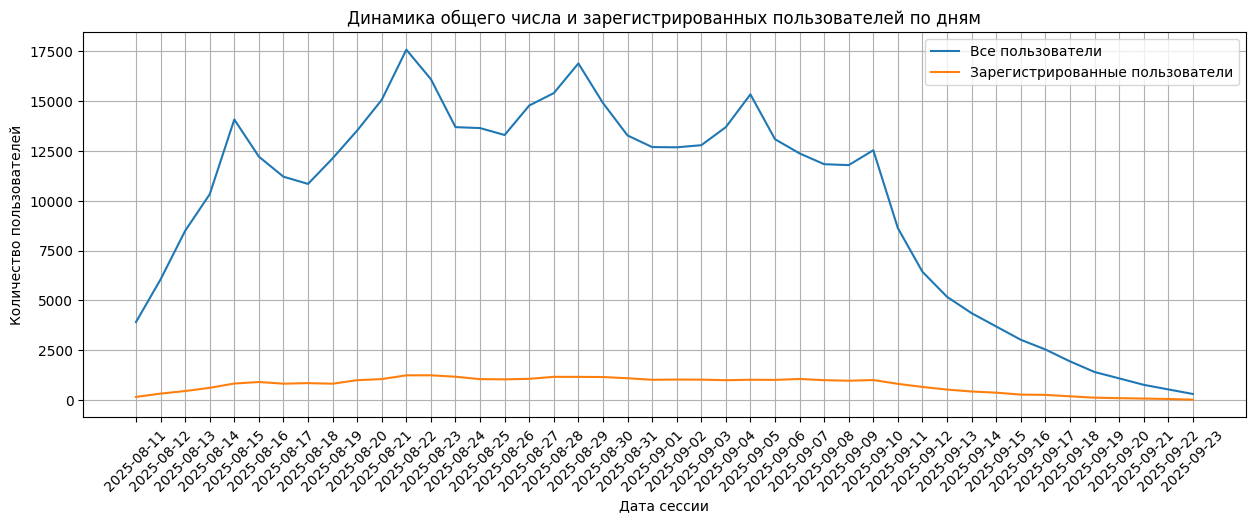

In [5]:
plt.figure(figsize=(15, 5))
plt.plot(total_users, label = 'Все пользователи')
plt.plot(registered_users, label = 'Зарегистрированные пользователи')

plt.title('Динамика общего числа и зарегистрированных пользователей по дням')
plt.legend()
plt.xlabel('Дата сессии')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)   
plt.grid()
plt.show()

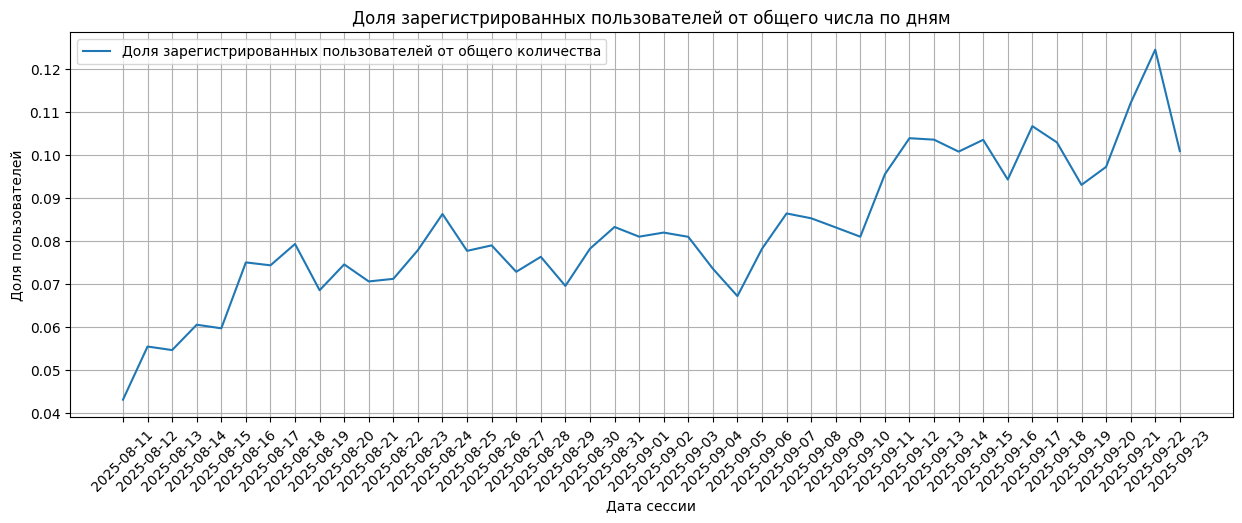

In [6]:
plt.figure(figsize=(15, 5))
plt.plot(registered_share, label = 'Доля зарегистрированных пользователей от общего количества')

plt.title('Доля зарегистрированных пользователей от общего числа по дням')
plt.xlabel('Дата сессии')
plt.ylabel('Доля пользователей')
plt.xticks(rotation=45)   
plt.legend()
plt.grid()
plt.show()

### Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках исследования было проанализовано число просмотренных страниц во время первых сессий пользователей:
- Найдено количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

- Рассчитана доля успешных первых сессий (сессий, где было просмотрено 4 или более страниц).

In [7]:
#Определяем количество первых сессий для каждого числа просмотренных страниц:
first_counter = sessions_history[sessions_history['session_number']== 1].groupby('page_counter')['session_number'].sum()
first_counter

page_counter
1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: session_number, dtype: int64

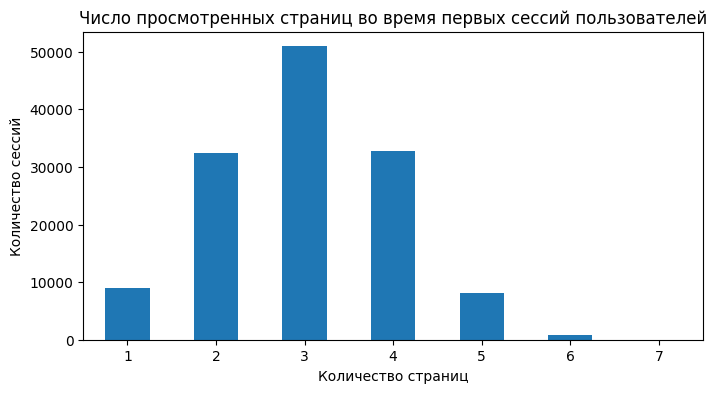

In [8]:
plt.figure(figsize = (8, 4))
first_counter.plot(kind = 'bar')

plt.title('Число просмотренных страниц во время первых сессий пользователей')
plt.xlabel('Количество страниц')
plt.ylabel('Количество сессий')
plt.xticks(rotation=0)   
plt.show()

In [9]:
# Выделяем успешные сессии:
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

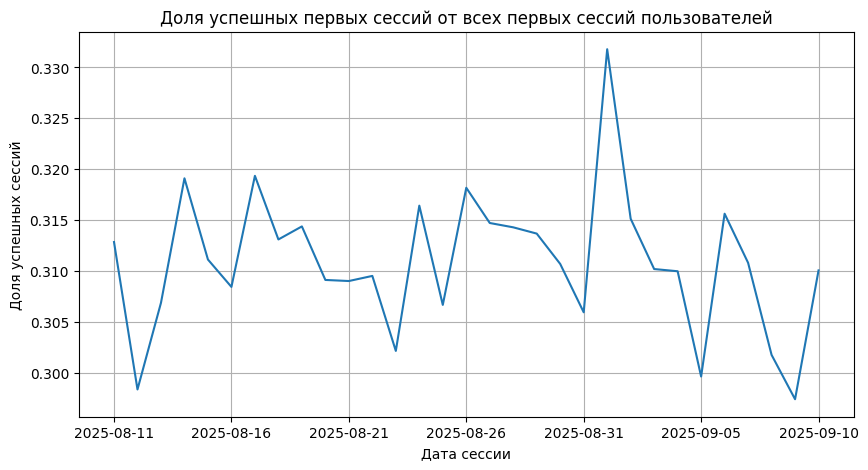

In [10]:
# Находим долю успешных первых сессий:
good_fist_share = sessions_history[sessions_history['session_number']== 1].groupby('session_date')['good_session'].mean()

plt.figure(figsize = (10, 5))
good_fist_share.plot(kind = 'line')
plt.title('Доля успешных первых сессий от всех первых сессий пользователей')
plt.xlabel('Дата сессии')
plt.ylabel('Доля успешных сессий')  
plt.grid()
plt.show()

## Подготовка к тесту
При планировании теста было проделано несколько важных шагов:

- Определена целевая метрика.

- Рассчитан необходимый минимальный размер выборки.

- Исходя из текущих значений трафика рассчитана необходимая длительность проведения теста.

### Расчёт размера выборки

Чтобы определить размер выборки, необходимый для обнаружения статистически значимого различия, были заданы следующие параметры:
- **Уровень значимости ($\alpha$):** 0.05
- **Вероятность ошибки II рода ($\beta$):** 0.20
- **Мощность теста ($1 - \beta$):** 0.80
- **Минимальный обнаруживаемый эффект (MDE):** 3% (в расчётах выражен как относительное изменение / десятичная дробь)

Расчёт размера выборки проводился с использованием метода `solve_power()` класса `NormalIndPower` из модуля `statsmodels.stats.power`.

In [11]:
# Задаём параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = (p * 0.03)  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


### Расчёт длительности A/B-теста

На основе необходимого размера выборки для каждой группы и исторического среднего количества пользователей был рассчитан ожидаемый срок проведения эксперимента:

- Рассчитано среднее ежедневное количество уникальных активных пользователей в приложении.
- Определена длительность теста путём деления суммарного необходимого размера выборки для всех групп на средний дневной трафик, с округлением в большую сторону до целого дня.

In [12]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = (sessions_history.groupby('session_date')['user_id'].nunique()).mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(sample_size*2/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {round(avg_daily_users,0)} пользователей в день составит {test_duration} дней.")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.0 пользователей в день составит 9 дней.


## Мониторинг А/В-теста

### Проверка распределения пользователей

После запуска A/B-теста были собраны предварительные данные за начальный период наблюдений. На этом этапе было важно убедиться в корректности работы механизма сплитования трафика и сбалансированности экспериментальных групп:

- Загрузили первичный датасет с результатами теста из файла `datasets/sessions_project_test_part.csv` в датафрейм `sessions_test_part`.
- Рассчитали количество уникальных пользователей, распределённых в каждую из экспериментальных групп (`A` и `B`), за первый день наблюдений.
- Вычислили относительное процентное различие между размерами групп по формуле:
$$P = 100 \cdot \frac{\vert{}A - B\vert{}}{A}$$
- Визуализировали сравнение размеров групп для оценки возможного дисбаланса выборок.

In [13]:
# Импортируем данные: 
sessions_test_part = pd.read_csv('datasets/sessions_project_test_part.csv')

In [31]:
#Определяем количество уникальных пользователей в каждой группе за каждый день:
test_summary = sessions_test_part.groupby(['session_date', 'test_group'])['user_id'].nunique().unstack()
#Находим процентную разницу в размере групп:
test_summary['A_B_percent'] = round(100 * ((test_summary['A'] - test_summary['B']) / test_summary['A']), 2)

#Выводим данные за первый день:
print(f"Количество пользователей в контрольной группе: {test_summary['A'].iloc[0]}.")
print(f"Количество пользователей в экспериментальной группе: {test_summary['B'].iloc[0]}.")
print(f"Процентная разница в количестве пользователей в группах A и B: {test_summary['A_B_percent'].iloc[0]}%.")

Количество пользователей в контрольной группе: 1477.
Количество пользователей в экспериментальной группе: 1466.
Процентная разница в количестве пользователей в группах A и B: 0.74%.


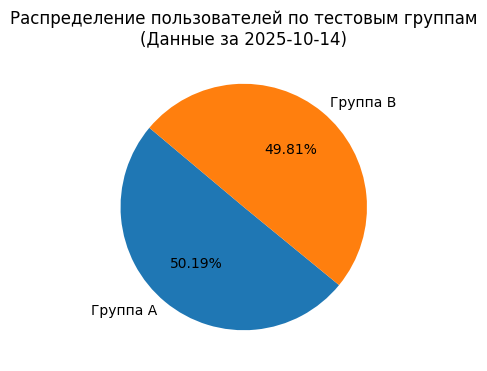

In [15]:
sizes = [test_summary['A'].iloc[0], test_summary['B'].iloc[0]]
labels = ['Группа A', 'Группа B']


plt.figure(figsize=(4, 4))
plt.pie(
    sizes, 
    labels=labels, 
    autopct='%1.2f%%',
    startangle=140     
)


plt.title(f"Распределение пользователей по тестовым группам\n(Данные за {test_summary.index[0]})")
plt.show()

### Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, важно было убедиться в том, что группы независимы, то есть никто из пользователей случайно не попал в обе группы одновременно.

In [16]:
#Поиск пересечения между пользователями в группах:
group_A = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id']
group_B = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id']
intersection = list(set(group_A) & set(group_B))

if not intersection:
    print('Списки не пересекаются.')
else:
    print("Пользователи в обеих группах:", intersection)

Списки не пересекаются.


### Равномерность разделения пользователей по устройствам и регионам
Чтобы убедиться в корректности рандомизации и отсутствии систематической ошибки отбора (selection bias), была оценена сбалансированность категориальных признаков между экспериментальными группами:

- Рассчитали долю каждого типа устройств среди пользователей в контрольной (Group A) и тестовой (Group B) группах, а также построили графики для сравнения распределения устройств между группами A и B.
- Вычислили долю пользователей из каждого региона для контрольной и тестовой групп и визуализировали сравнение региональных долей между группами A и B.

In [17]:
#Определяем количество уникальных пользователей для каждой группы и типа устройства:
devices = sessions_test_part.groupby(['test_group', 'device'])['user_id'].nunique().unstack().T
#Определяем долю каждого типа устройства:
devices_share = round(devices/devices.sum(), 2)

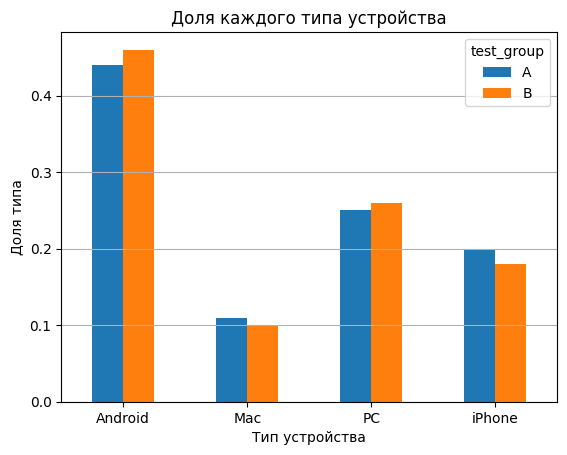

In [18]:
devices_share.plot(kind = 'bar', title = 'Доля каждого типа устройства')

plt.xlabel('Тип устройства')
plt.ylabel('Доля типа')
plt.xticks(rotation=0) 
plt.grid(axis='y')
plt.show()

In [19]:
#Определяем количество уникальных пользователей для каждой группы и региона:
regions = sessions_test_part.groupby(['test_group', 'region'])['user_id'].nunique().unstack().T

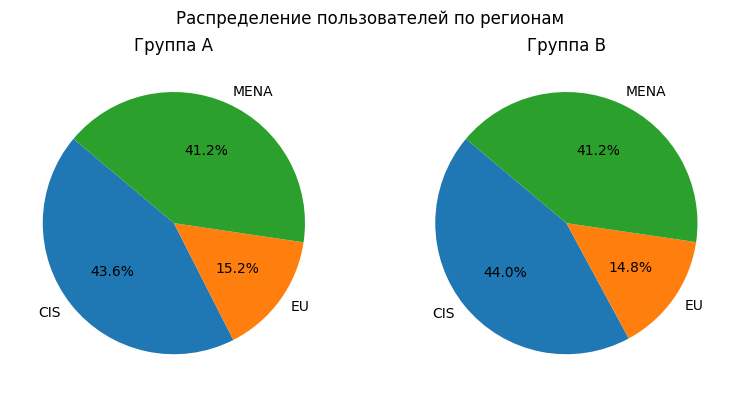

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.pie(regions['A'], labels=regions.index, autopct='%1.1f%%', startangle=140)
ax1.set_title('Группа A')

ax2.pie(regions['B'], labels=regions.index, autopct='%1.1f%%', startangle=140)
ax2.set_title('Группа B')

fig.suptitle('Распределение пользователей по регионам')
plt.tight_layout()
plt.show()

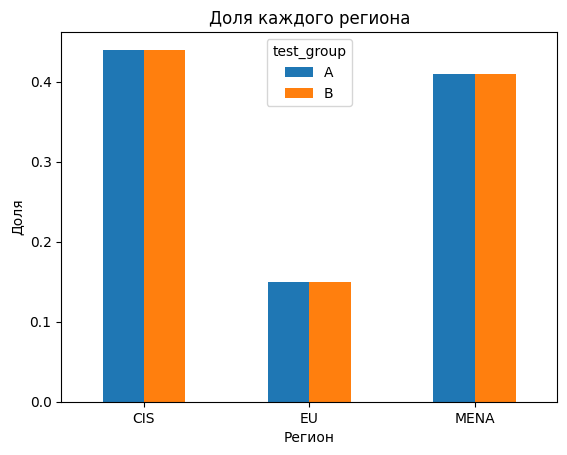

In [21]:
#Определяем долю каждого региона в группах:
regions_share = round(regions/regions.sum(), 2)
regions_share.plot(kind = 'bar', title = 'Доля каждого региона')

plt.xlabel('Регион')
plt.ylabel('Доля')
plt.xticks(rotation=0) 
plt.show()

### Вывод после проверки A/B-теста

На основе первичного анализа данных о параметрах A/B-теста были сделаны следующие выводы относительно сбалансированности выборок и корректности проведения эксперимента:
- **Сбалансированность размеров групп**: Оценено распределение пользователей между контрольной и тестовой группами за первый день наблюдений. Процентное различие в размерах групп остаётся в пределах допустимой нормы, что подтверждает равномерную работу алгоритма сплитования трафика.
- **Независимость выборок**: Пересечений пользователей между экспериментальными группами не обнаружено. Выборки строго независимы, что исключает риск взаимного загрязнения данных.
- **Распределение категориальных признаков**:
  - **Типы устройств**: Соотношение пользователей по категориям устройств идентично в группах A и B.
  - **Географические регионы**: Региональная структура демонстрирует стабильные доли пользователей в обеих группах, подтверждая сбалансированное географическое представление.
**Вывод**: Инфраструктура A/B-тестирования работает корректно, без технических аномалий и дисбаланса выборок. Требования к сплитованию, независимости выборок и сбалансированности признаков полностью выполнены, что позволяет продолжать эксперимент согласно плану.

## Проверка результатов A/B-теста

A/B-тест завершён, доступны полные данные за все дни проведения эксперимента. На этом этапе анализа необходимо убедиться в корректности теста и интерпретировать результаты.

### Получение результатов теста и подсчёт основной метрики

- Полные данные за всё время проведения эксперимента загружены в датафрейм `sessions_test` из CSV-файла `sessions_project_test.csv`.

- В датафрейме `sessions_test` создан дополнительный столбец `good_session` с бинарным признаком: значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [22]:
#Загружаем данные: 
sessions_test = pd.read_csv('datasets/sessions_project_test.csv')

In [23]:
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


In [24]:
# Выводим структуру датафрейма: 
print(sessions_test.info())
print('Данные предоставлены за', sessions_test['session_date'].nunique(), 'дней.')

#Подсчитываем уникальных пользователей в каждой группе. 
group_a = sessions_test[sessions_test['test_group']=='A']['user_id'].nunique()
group_b = sessions_test[sessions_test['test_group']=='B']['user_id'].nunique()
print(f'group_a: {group_a} уникальных пользователей, group_b: {group_b} уникальных пользователей.')

<class 'pandas.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   user_id            100005 non-null  str  
 1   session_id         100005 non-null  str  
 2   session_date       100005 non-null  str  
 3   session_start_ts   100005 non-null  str  
 4   install_date       100005 non-null  str  
 5   session_number     100005 non-null  int64
 6   registration_flag  100005 non-null  int64
 7   page_counter       100005 non-null  int64
 8   region             100005 non-null  str  
 9   device             100005 non-null  str  
 10  test_group         100005 non-null  str  
dtypes: int64(3), str(8)
memory usage: 8.4 MB
None
Данные предоставлены за 20 дней.
group_a: 15163 уникальных пользователей, group_b: 15416 уникальных пользователей.


In [32]:
# Создаём столбец с бинарным определением удачной сессии:
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

### Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

**Целевой метрикой** в данном тесте можно выбрать долю успешных первых сессий, поскольку именно первое впечатление может привести к регистрации на платформе и дальнейшей покупке подписки. <br>
**Прокси-метрикой** может быть количество просмотренных страниц, поскольку увеличение их количества может сигнализировать об успешной работе алгоритма ещё до вычисления конверсии в удачные сессии. <br>
**Барьерной метрикой** может быть среднее количество сессий на пользователя. Если количество повторных сессий снижается, можно говорить о потерях охвата и прибыли в долгосрочной перспективе даже при удачной первой сессии.

**Нулевая гипотеза:** доли успешных первых сессий между группами А и B не различаются. <br>
**Альтернативная гипотеза:** доля успешных первых сессий в группе А < доли успешных первых сессий в группе B. 

### Сравнение доли успешных первых сессий

Проведена оценка значений целевой метрики в обеих группах. 

In [26]:
#Подсчёт доли успешных первых сессий в группах:
good_first_session_A_share = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number']==1)]['good_session'].mean()
good_first_session_B_share = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number']==1)]['good_session'].mean()
print('Доля успешных первых сессий в группе А:', round(good_first_session_A_share, 3))
print('Доля успешных первых сессий в группе B:', round(good_first_session_B_share, 3))
print('Разница составила', round(good_first_session_A_share - good_first_session_B_share, 3))

Доля успешных первых сессий в группе А: 0.316
Доля успешных первых сессий в группе B: 0.315
Разница составила 0.001


### Оценка статистической значимости изменения ключевой метрики

Несмотря на то что наблюдаемые доли успешных первых сессий в группах оказались близки, бизнес-решения нельзя принимать только на основе точечных оценок. Для оценки статистической значимости различий в ключевой метрике между группами было проведено тестирование гипотез:

- Проведён двухвыборочный Z-тест для долей с целью оценки статистической значимости изменения метрики.
- Полученное значение $p$-value сравнили с заранее выбранным уровнем значимости ($\alpha = 0.05$).

In [33]:
# Задаём уровень статистической значимости (alpha = 5%):
alpha = 0.05
# Подсчитываем общее количество первых сессий в группах:
n_a = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number']==1)]['good_session'].count()
n_b = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number']==1)]['good_session'].count()
# Подсчитываем количество успешных первых сессий в группах:
m_a = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number']==1)]['good_session'].sum()
m_b = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number']==1)]['good_session'].sum()

# Проводим односторонний Z-тест для двух независимых долей:
stat_ztest, p_value_ztest = proportions_ztest(
    nobs = [n_a, n_b], 
    count = [m_a, m_b],
    alternative = 'smaller'
)
if p_value_ztest>alpha:
    print(f'{round(p_value_ztest, 2)}>{alpha}.', 'Не удалось отклонить нулевую гипотезу. Статистически значимых различий в доле успешных первых сессий между группами не обнаружено.')
else:
    print(f'{round(p_value_ztest,2)}<{alpha}.','Отклоняем нулевую гипотезу. Новый алгоритм привёл к повышению доли успешных первых сессий.')

0.58>0.05. Не удалось отклонить нулевую гипотезу. Статистически значимых различий в доле успешных первых сессий между группами не обнаружено.


### Вывод по результатам A/B-эксперимента


На основе статистического анализа проведённого A/B-теста сформированы итоговые результаты и рекомендации для продуктовой команды и команды разработки:

- **Параметры и объём эксперимента:**
  - **Расчётные требования:** Минимально необходимый размер выборки составлял 41 040 пользователей на группу при расчётной длительности теста в 9 дней.
  - **Фактическое проведение:** Эксперимент продолжался 20 дней, в течение которых было собрано 100 005 записей о сессиях (приблизительно по 15 000 уникальных пользователей в каждой группе).
- **Влияние на метрику и статистическая значимость:**
  - Рассчитанное значение $p$-value для двухвыборочного Z-теста составило **0.58**, что существенно превышает выбранный уровень значимости ($\alpha = 0.05$).
  - Таким образом, у нас нет оснований отвергнуть нулевую гипотезу. Статистически значимых доказательств того, что новый алгоритм рекомендаций увеличил долю успешных первых сессий, не обнаружено.
- **Продуктовое решение:**
  - **Рекомендация:** **Не раскатывать** новый алгоритм рекомендаций на продакшен. Предложенные изменения не продемонстрировали измеримого положительного влияния на вовлечённость пользователей на начальном этапе и не оправдывают затрат на внедрение и поддержку.